# Data Scientist Professional Practical Exam: Recipe Site Traffic

**Business question.** Tasty Bytes wants to choose recipes for its homepage that are likely to receive high traffic. The decision target is that at least 80% of selected recipes are genuinely High traffic. I treat this as a **binary classification** problem and report both the share of selected recipes that are High (**precision**) and how many recipes the policy selects (**coverage**).

This report contains the complete Python analysis, its outputs, and the written interpretation. It uses the supplied 947-row public CSV. The source has no publication dates, homepage exposure history, or subscription outcomes, so this project evaluates historical traffic labels rather than causal impact on subscriptions.


## Data validation and cleaning

The unit of analysis is one recipe. The code below loads the dataset without changing the source CSV. A DataLab workspace can use its attached CSV; if absent, the notebook downloads the public file named in the brief.

In [1]:
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


ROOT = Path.cwd()
SOURCE = ROOT / "recipe_site_traffic_2212.csv"
FEATURES = ["calories", "carbohydrate", "sugar", "protein", "category", "servings"]
NUMERIC = ["calories", "carbohydrate", "sugar", "protein", "servings"]
PALETTE = {"navy": "#17324D", "teal": "#168E8B", "amber": "#D69E42", "coral": "#CC6B5A"}
SEED = 42



# DataLab usually includes the CSV; fetch the same public source when it does not.
if not SOURCE.exists():
    from urllib.request import urlretrieve
    urlretrieve("https://s3.amazonaws.com/talent-assets.datacamp.com/recipe_site_traffic_2212.csv", SOURCE)
raw = pd.read_csv(SOURCE, dtype={"recipe": str, "category": str,
                                 "servings": str, "high_traffic": str})
print(f"Loaded {len(raw)} recipes and {len(raw.columns)} columns from {SOURCE.name}")
print("SHA-256:", hashlib.sha256(SOURCE.read_bytes()).hexdigest())
display(raw.head())


Loaded 947 recipes and 8 columns from recipe_site_traffic_2212.csv
SHA-256: da2c83dd061fa7cfc85c9a5ce7a92682db14da721cac09eb0d166a42d49c9733


,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,001,NaN,NaN,NaN,NaN,Pork,6,High
1,002,35.48,38.56,0.66,0.92,Potato,4,High
2,003,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,004,97.03,30.56,38.63,0.02,Beverages,4,High
4,005,27.05,1.85,0.80,0.53,Beverages,4,NaN


In [2]:
def source_profile(raw: pd.DataFrame) -> dict:
    expected_categories = {
        "Lunch/Snacks", "Beverages", "Potato", "Vegetable", "Meat",
        "Chicken", "Pork", "Dessert", "Breakfast", "One Dish Meal",
    }
    numeric_missing = raw[["calories", "carbohydrate", "sugar", "protein"]].isna()
    return {
        "source_url": "https://s3.amazonaws.com/talent-assets.datacamp.com/recipe_site_traffic_2212.csv",
        "source_sha256": hashlib.sha256(SOURCE.read_bytes()).hexdigest(),
        "rows": int(len(raw)),
        "columns": list(raw.columns),
        "recipe_missing": int(raw["recipe"].isna().sum()),
        "recipe_duplicate_ids": int(raw["recipe"].duplicated().sum()),
        "numeric_missing_by_column": {col: int(numeric_missing[col].sum()) for col in numeric_missing},
        "rows_all_four_nutrients_missing": int(numeric_missing.all(axis=1).sum()),
        "category_levels": sorted(raw["category"].dropna().unique().tolist()),
        "unexpected_category_levels": sorted(set(raw["category"].dropna()) - expected_categories),
        "servings_non_numeric_rows": int((~raw["servings"].str.fullmatch(r"\d+")).sum()),
        "servings_non_numeric_values": sorted(raw.loc[~raw["servings"].str.fullmatch(r"\d+"), "servings"].unique().tolist()),
        "target_values": {"High": int(raw["high_traffic"].eq("High").sum()),
                          "blank": int(raw["high_traffic"].isna().sum())},
        "unexpected_target_values": sorted(set(raw["high_traffic"].dropna()) - {"High"}),
    }


def prepare(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    # The brief marks high traffic as High and leaves all other values blank.
    # Treat blank as not-High provisionally; this is not a confirmed negative label.
    clean = raw.copy()
    clean["servings"] = clean["servings"].str.extract(r"^(\d+)")[0].astype(float)
    if clean["servings"].isna().any():
        raise ValueError("Unexpected unparseable serving value")
    # Retain the observed Chicken Breast level instead of silently merging it.
    # The brief says ten categories, but the source has eleven.
    y = clean["high_traffic"].eq("High").astype(int)
    return clean[FEATURES], y




In [3]:
expected = ["recipe","calories","carbohydrate","sugar","protein","category","servings","high_traffic"]
assert list(raw.columns) == expected, f"Unexpected columns: {list(raw.columns)}"
p = source_profile(raw)
numeric = ["calories","carbohydrate","sugar","protein"]
checks = []
checks.append(["recipe","Identifier",len(raw)-raw.recipe.nunique(),int(raw.recipe.isna().sum()),
               "Unique and complete; excluded from predictors"])
for col in numeric:
    values = pd.to_numeric(raw[col], errors="coerce")
    invalid = int(((values < 0) & values.notna()).sum())
    checks.append([col,"Numeric measurement",invalid,int(values.isna().sum()),
                   "52 missing; retain rows and fit median imputer on training only"])
checks.append(["category","Category",len(p["unexpected_category_levels"]),int(raw.category.isna().sum()),
               "11 observed; retain Chicken Breast as its own level"])
servings_num = pd.to_numeric(raw.servings.str.extract(r"^(\d+)")[0], errors="coerce")
checks.append(["servings","Positive count",int((servings_num.le(0) | servings_num.isna()).sum()),
               int(raw.servings.isna().sum()),"3 values include 'as a snack'; use leading integer"])
checks.append(["high_traffic","Outcome: High or blank",len(p["unexpected_target_values"]),
               int(raw.high_traffic.isna().sum()),
               "373 blanks treated provisionally as not High"])
validation = pd.DataFrame(checks,columns=["column","expected type","invalid / extra","missing","treatment"])
display(validation)
print("All-four-nutrient missing rows:",p["rows_all_four_nutrients_missing"])
print("Category levels:",p["category_levels"])
print("Non-standard servings:",p["servings_non_numeric_values"])
print("Target counts:",p["target_values"])
assert raw.recipe.notna().all() and raw.recipe.is_unique
assert (raw[numeric].dropna() >= 0).all().all()
assert servings_num.notna().all() and servings_num.gt(0).all()
assert not p["unexpected_target_values"]


,column,expected type,invalid / extra,missing,treatment
0,recipe,Identifier,0,0,Unique and complete; excluded from predictors
1,calories,Numeric measurement,0,52,52 missing; retain rows and fit median imputer...
2,carbohydrate,Numeric measurement,0,52,52 missing; retain rows and fit median imputer...
3,sugar,Numeric measurement,0,52,52 missing; retain rows and fit median imputer...
4,protein,Numeric measurement,0,52,52 missing; retain rows and fit median imputer...
5,category,Category,1,0,11 observed; retain Chicken Breast as its own ...
6,servings,Positive count,0,0,3 values include 'as a snack'; use leading int...
7,high_traffic,Outcome: High or blank,0,373,373 blanks treated provisionally as not High


All-four-nutrient missing rows: 52
Category levels: ['Beverages', 'Breakfast', 'Chicken', 'Chicken Breast', 'Dessert', 'Lunch/Snacks', 'Meat', 'One Dish Meal', 'Pork', 'Potato', 'Vegetable']
Non-standard servings: ['4 as a snack', '6 as a snack']
Target counts: {'High': 574, 'blank': 373}


**Validation finding.** All 947 recipe IDs are present and unique. Each nutrient column has 52 missing values, and these are the same 52 rows. The brief lists ten categories, while the file contains eleven because **Chicken Breast** appears separately. I keep that observed category rather than silently merging it. Three servings values include “as a snack”; extracting the leading count keeps those recipes.

The **373 blank traffic values are the main unresolved data issue**. For this exercise I provisionally code them as not High, but the product team must confirm that blanks represent negative outcomes rather than missing labels before using this model. The 52 nutrient-missing rows have 39/52 (75%) High labels versus 535/895 (59.8%) among complete rows, so the missingness pattern deserves further investigation. No timestamp exists to assess freshness or changes over time.


## Exploratory analysis

The bar chart and histogram describe single variables. The category comparison is a two-variable graphic: category and High-traffic rate. These are associations, not evidence that a category causes higher traffic.

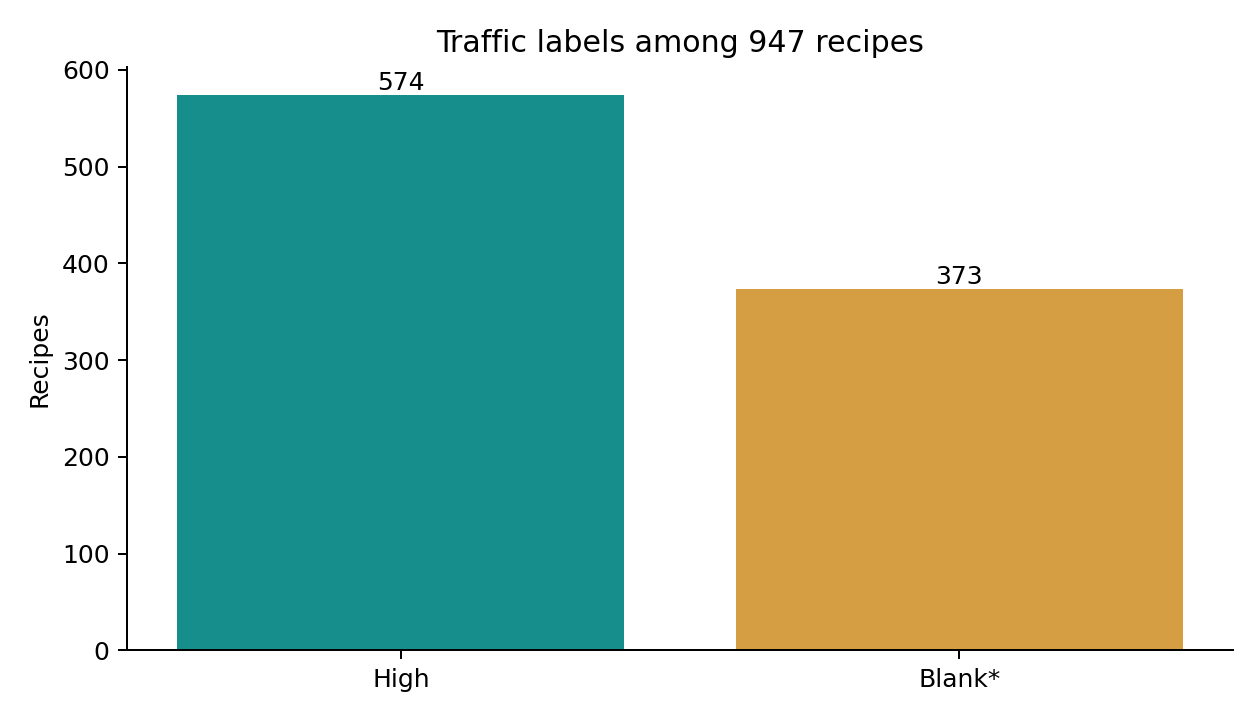

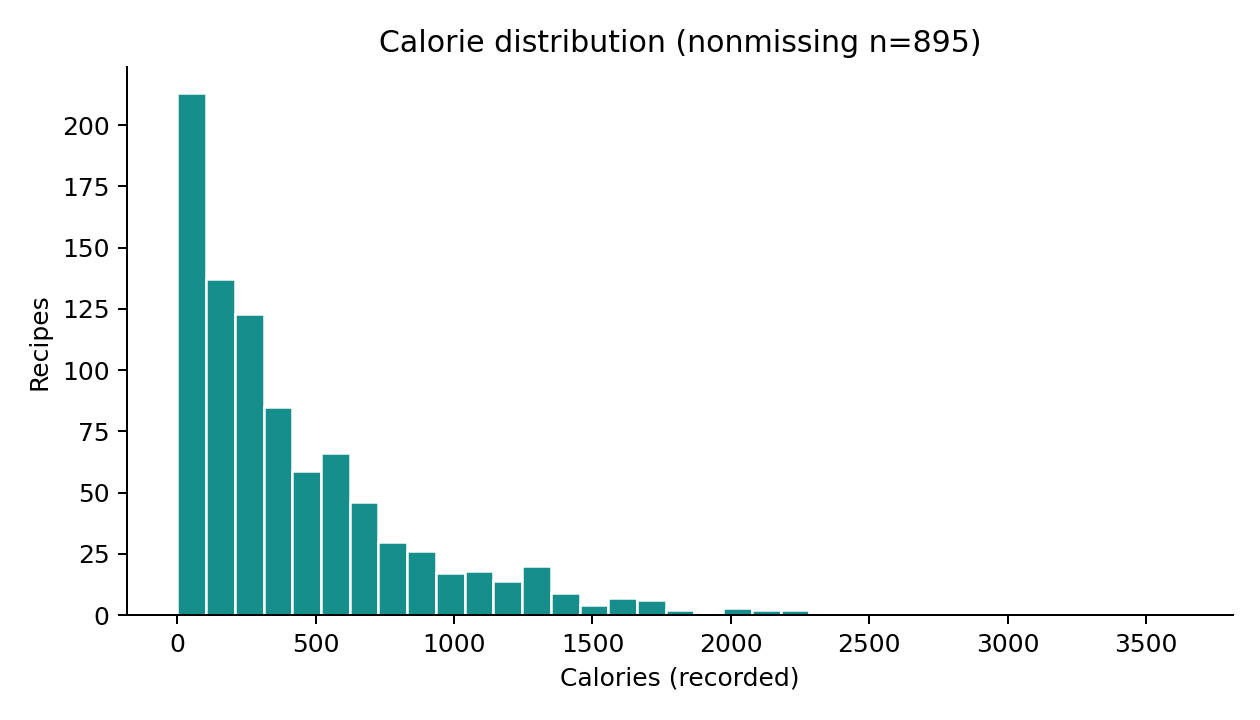

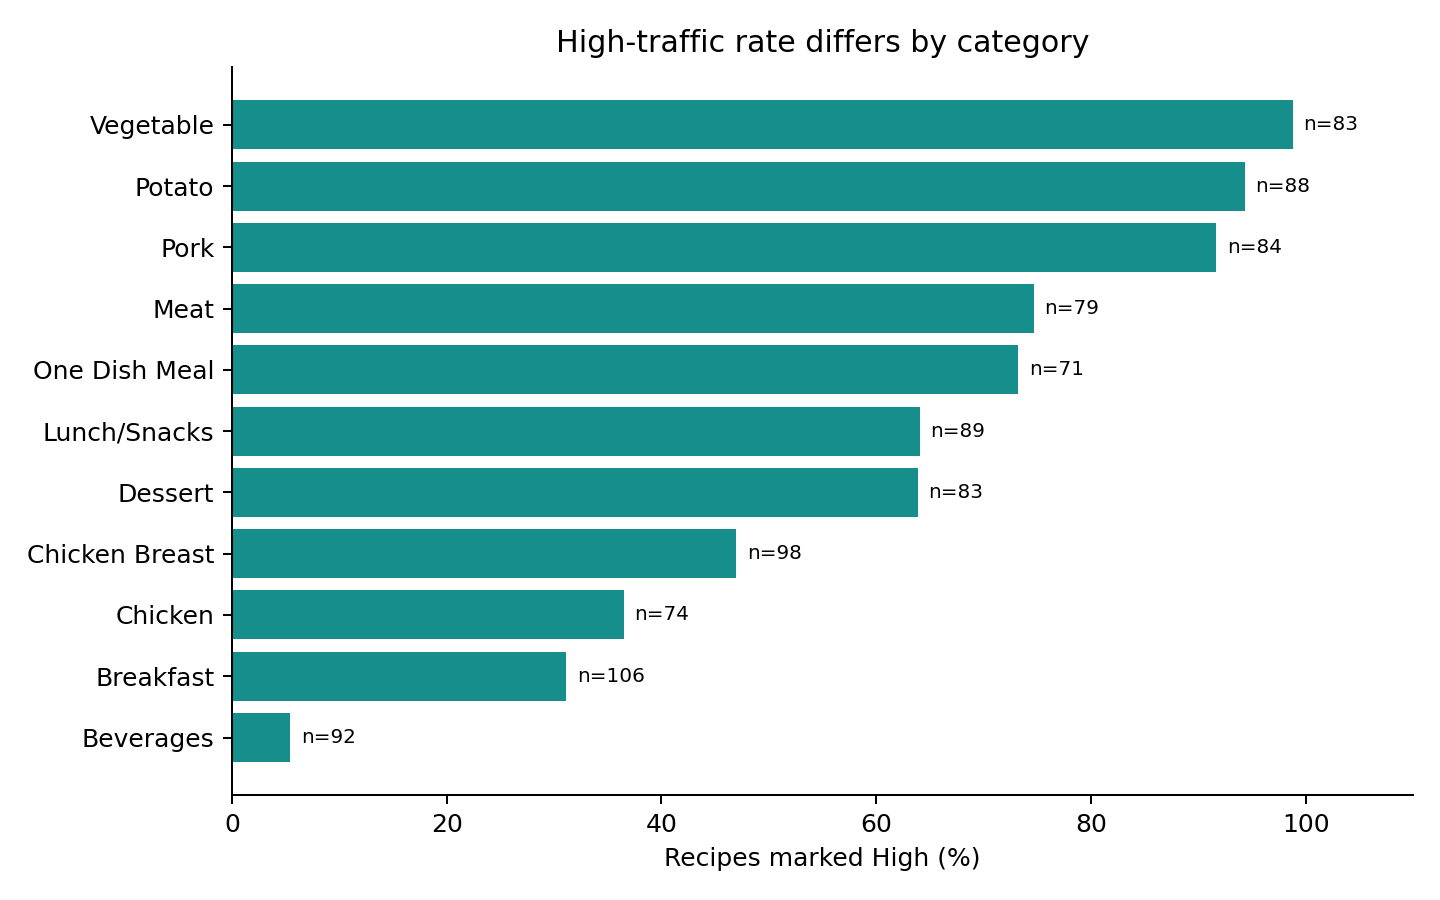

,category,recipes,high_rate
0,Beverages,92,5.4
1,Breakfast,106,31.1
2,Chicken,74,36.5
3,Chicken Breast,98,46.9
4,Dessert,83,63.9
5,Lunch/Snacks,89,64.0
7,One Dish Meal,71,73.2
6,Meat,79,74.7
8,Pork,84,91.7
9,Potato,88,94.3


In [4]:
from IPython.display import display, Image
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,
                     "axes.spines.top":False,"axes.spines.right":False})
traffic_counts = raw.high_traffic.fillna("Blank*").value_counts().reindex(["High","Blank*"])
fig, ax = plt.subplots(figsize=(7,4))
bars=ax.bar(traffic_counts.index,traffic_counts.values,color=["#168E8B","#D69E42"])
ax.bar_label(bars); ax.set(ylabel="Recipes",title="Traffic labels among 947 recipes")
fig.tight_layout()
fig.savefig(ROOT / "label_balance.png", dpi=180)
display(Image(filename=str(ROOT / "label_balance.png"), width=650))
plt.close(fig)

fig, ax = plt.subplots(figsize=(7,4))
calories=raw.calories.dropna()
ax.hist(calories,bins=35,color="#168E8B",edgecolor="white")
ax.set(xlabel="Calories (recorded)",ylabel="Recipes",
       title=f"Calorie distribution (nonmissing n={len(calories)})")
fig.tight_layout()
fig.savefig(ROOT / "calorie_distribution.png", dpi=180)
display(Image(filename=str(ROOT / "calorie_distribution.png"), width=650))
plt.close(fig)

category_rates = (raw.assign(is_high=raw.high_traffic.eq("High").astype(int))
                  .groupby("category",as_index=False)
                  .agg(recipes=("recipe","size"),high_rate=("is_high","mean"))
                  .sort_values("high_rate"))
fig, ax = plt.subplots(figsize=(8,5))
bars=ax.barh(category_rates.category,100*category_rates.high_rate,color="#168E8B")
for bar,n in zip(bars,category_rates.recipes):
    ax.text(bar.get_width()+1,bar.get_y()+bar.get_height()/2,f"n={n}",va="center",fontsize=8)
ax.set(xlabel="Recipes marked High (%)",title="High-traffic rate differs by category",xlim=(0,110))
fig.tight_layout()
fig.savefig(ROOT / "category_high_rate.png", dpi=180)
display(Image(filename=str(ROOT / "category_high_rate.png"), width=740))
plt.close(fig)
display(category_rates.assign(high_rate=lambda x:(x.high_rate*100).round(1)))


**Exploratory findings.** 574 of 947 recipes (60.6%) are marked High; the other 373 have blank labels. Calories are strongly right-skewed, so the mean alone would be a poor summary. High-label rates vary markedly across categories, but category sizes differ and the historical homepage-selection process may have shaped the sample. I use category as a predictor, without treating this pattern as causal or automatically favoring one category.


## Model development

I compare **logistic regression**, a transparent linear baseline, with a **random forest**, which can learn nonlinear relationships and interactions. An all-High dummy policy is the business reference. Recipe ID is excluded. The 60/20/20 stratified split separates training, validation, and an untouched test set. Numeric imputation and encoding are fitted only in training pipelines.

The selection rule is chosen using validation data: require at least 20 selections, seek precision of at least 80%, and among thresholds that pass choose the one selecting the most recipes. Model choice follows that same validation rule. The test set is evaluated only after the model and threshold are fixed.


In [5]:
def preprocessing(scale: bool) -> ColumnTransformer:
    numeric_steps = [("median", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer(
        [("numeric", Pipeline(numeric_steps), NUMERIC),
         ("category", OneHotEncoder(handle_unknown="ignore"), ["category"])],
        remainder="drop",
    )


def evaluate(y_true, probabilities, threshold: float) -> dict:
    y_pred = np.asarray(probabilities) >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "threshold": round(float(threshold), 4),
        "true_negative": int(tn), "false_positive": int(fp),
        "false_negative": int(fn), "true_positive": int(tp),
        "selected_count": int(y_pred.sum()),
        "selection_coverage": round(float(y_pred.mean()), 4),
        "precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        "f1": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "balanced_accuracy": round(float(balanced_accuracy_score(y_true, y_pred)), 4),
    }


def wilson_interval(successes: int, total: int, z: float = 1.96) -> list[float] | None:
    if total == 0:
        return None
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    half_width = z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / denominator
    return [round(float(center - half_width), 4), round(float(center + half_width), 4)]


def best_validation_threshold(y_true, probabilities, minimum_selected: int = 20) -> dict:
    options = [evaluate(y_true, probabilities, t) for t in np.linspace(0.30, 0.99, 140)]
    eligible = [o for o in options if o["selected_count"] >= minimum_selected]
    passing = [o for o in eligible if o["precision"] >= 0.80]
    pool = passing or eligible
    if not pool:
        raise ValueError("No validation threshold selects enough recipes")
    if passing:
        chosen = max(pool, key=lambda o: (o["selected_count"], o["precision"], -o["threshold"]))
    else:
        chosen = max(pool, key=lambda o: (o["precision"], o["selected_count"]))
    return {**chosen, "met_80_percent_precision_on_validation": bool(passing)}




In [6]:
def plot_evidence(raw: pd.DataFrame, y: pd.Series, model_scores: dict, selected: dict) -> None:
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "axes.labelcolor": PALETTE["navy"], "text.color": PALETTE["navy"]})

    fig, ax = plt.subplots(figsize=(7, 4.3))
    counts = y.value_counts().reindex([0, 1], fill_value=0)
    bars = ax.bar(["Not marked High*", "High"], counts, color=[PALETTE["amber"], PALETTE["teal"]])
    ax.bar_label(bars, padding=4)
    ax.set_ylabel("Recipes")
    ax.set_title("Traffic label balance (n=947)", loc="left", weight="bold")
    ax.set_ylim(0, 650)
    fig.text(.11, .01, "*Blank traffic treated as not-High for this exercise; confirm with the product team.", fontsize=8)
    fig.tight_layout(rect=[0, .05, 1, 1]); fig.savefig(ROOT / "label_balance.png", dpi=180); plt.close(fig)

    calories = raw["calories"].dropna()
    fig, ax = plt.subplots(figsize=(7, 4.3))
    ax.hist(calories, bins=35, color=PALETTE["teal"], edgecolor="white")
    ax.set_xlabel("Calories (recorded)")
    ax.set_ylabel("Recipes")
    ax.set_title(f"Calorie distribution (nonmissing n={len(calories)})", loc="left", weight="bold")
    fig.tight_layout(); fig.savefig(ROOT / "calorie_distribution.png", dpi=180); plt.close(fig)

    by_category = pd.DataFrame({"category": raw["category"], "high": y}).groupby("category").agg(
        high_rate=("high", "mean"), recipes=("high", "size")
    ).sort_values("high_rate")
    fig, ax = plt.subplots(figsize=(8, 5.5))
    bars = ax.barh(by_category.index, by_category.high_rate * 100, color=PALETTE["teal"])
    for bar, count in zip(bars, by_category.recipes):
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"n={count}", va="center", fontsize=8)
    ax.set_xlim(0, 110); ax.set_xlabel("Recipes marked High (%)")
    ax.set_title("High-traffic rate differs by category", loc="left", weight="bold")
    fig.tight_layout(); fig.savefig(ROOT / "category_high_rate.png", dpi=180); plt.close(fig)

    fig, ax = plt.subplots(figsize=(7.4, 4.5))
    for name, detail in model_scores.items():
        curve = detail["curve"]
        ax.plot([point["selection_coverage"] * 100 for point in curve],
                [point["precision"] * 100 for point in curve],
                label=name, linewidth=2, color=PALETTE["teal"] if name == "Logistic regression" else PALETTE["navy"])
    ax.axhline(80, color=PALETTE["coral"], linestyle="--", label="80% target")
    ax.set(xlabel="Validation recipes selected (%)", ylabel="Precision among selected (%)",
           title="Validation trade-off: precision versus selection coverage")
    ax.set_xlim(0, 100); ax.set_ylim(45, 101); ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(ROOT / "precision_coverage.png", dpi=180); plt.close(fig)

    test = selected["test"]
    fig, ax = plt.subplots(figsize=(5.4, 4.7))
    cm = np.array([[test["true_negative"], test["false_positive"]],
                   [test["false_negative"], test["true_positive"]]])
    ax.imshow(cm, cmap="Blues", vmin=0)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] >= 60 else PALETTE["navy"],
                    fontsize=17, weight="bold")
    ax.set_xticks([0, 1], ["Not High", "High"]); ax.set_yticks([0, 1], ["Not High", "High"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Observed")
    ax.set_title("Held-out test decisions", loc="left", weight="bold")
    fig.tight_layout(); fig.savefig(ROOT / "test_confusion_matrix.png", dpi=180); plt.close(fig)


def main() -> dict:
    raw = pd.read_csv(SOURCE, dtype={"recipe": str, "category": str, "servings": str, "high_traffic": str})
    expected_columns = ["recipe", "calories", "carbohydrate", "sugar", "protein", "category", "servings", "high_traffic"]
    if list(raw.columns) != expected_columns:
        raise ValueError(f"Unexpected source columns: {list(raw.columns)}")
    profile = source_profile(raw)
    if profile["recipe_duplicate_ids"] or profile["recipe_missing"] or profile["unexpected_target_values"]:
        raise ValueError("Identifier or target failed validation")
    X, y = prepare(raw)
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X, y, test_size=.20, stratify=y, random_state=SEED)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val, test_size=.25, stratify=y_train_val, random_state=SEED)

    models = {
        "Logistic regression": Pipeline([("preprocess", preprocessing(True)),
                                         ("model", LogisticRegression(max_iter=2000, random_state=SEED))]),
        "Random forest": Pipeline([("preprocess", preprocessing(False)),
                                    ("model", RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                                                      random_state=SEED, n_jobs=-1))]),
    }
    dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

    model_scores = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        val_prob = model.predict_proba(X_val)[:, 1]
        choice = best_validation_threshold(y_val, val_prob)
        curve = [evaluate(y_val, val_prob, t) for t in np.linspace(.30, .99, 140)]
        model_scores[name] = {
            "validation_at_half": evaluate(y_val, val_prob, .50),
            "validation_choice": choice,
            "curve": curve,
        }

    passing_models = [name for name, detail in model_scores.items()
                      if detail["validation_choice"]["met_80_percent_precision_on_validation"]]
    eligible_models = passing_models or list(model_scores)
    selected_name = max(eligible_models, key=lambda name: (
        model_scores[name]["validation_choice"]["selected_count"],
        model_scores[name]["validation_choice"]["precision"],
    )) if passing_models else max(eligible_models, key=lambda name: (
        model_scores[name]["validation_choice"]["precision"],
        model_scores[name]["validation_choice"]["selected_count"],
    ))
    selected_detail = model_scores[selected_name]
    # Holdout predictions are computed only after model and threshold selection.
    selected_test = evaluate(y_test, models[selected_name].predict_proba(X_test)[:, 1],
                             selected_detail["validation_choice"]["threshold"])
    dummy_test = evaluate(y_test, dummy.predict_proba(X_test)[:, 1], .50)
    selected = {
        "model": selected_name,
        "threshold_chosen_on_validation": selected_detail["validation_choice"]["threshold"],
        "met_80_percent_precision_on_validation": selected_detail["validation_choice"]["met_80_percent_precision_on_validation"],
        "validation": selected_detail["validation_choice"],
        "test": selected_test,
        "test_precision_wilson_95_percent": wilson_interval(selected_test["true_positive"], selected_test["selected_count"]),
    }
    output = {
        "brief": "Practical Exam - Recipe Site Traffic (Tasty Bytes)",
        "source_profile": profile,
        "label_assumption": "Blank high_traffic treated as not-High; must be confirmed before deployment.",
        "category_decision": "Retain Chicken Breast as an observed 11th level; do not silently merge with Chicken.",
        "servings_decision": "Extract leading integer from three 'as a snack' values; retain all rows.",
        "nutrition_decision": "Keep 52 rows with four missing nutrient fields; impute medians inside training pipeline only.",
        "split": {"train": len(X_train), "validation": len(X_val), "test": len(X_test),
                  "seed": SEED, "method": "stratified random 60/20/20"},
        "class_prevalence": round(float(y.mean()), 4),
        "dummy_test": dummy_test,
        "models": {name: {key: value for key, value in detail.items() if key != "curve"}
                   for name, detail in model_scores.items()},
        "selected": selected,
        "limits": ["No timestamps permit prospective validation.",
                   "The historical featured recipes were selected by a person; this sample may not represent all candidate recipes.",
                   "Traffic association does not establish that the recipe caused the increase or that subscriptions rose.",
                   "Blank traffic is an unconfirmed negative-label assumption."],
    }
    (ROOT / "analysis_results.json").write_text(json.dumps(output, indent=2), encoding="utf-8")
    plot_evidence(raw, y, model_scores, selected)
    print(json.dumps({"source_rows": len(raw), "split": output["split"],
                      "dummy_test": dummy_test, "selected": selected}, indent=2))
    return output




In [7]:
results=main()
comparison=pd.DataFrame([
 {"model":name,
  "validation threshold":d["validation_choice"]["threshold"],
  "validation precision":d["validation_choice"]["precision"],
  "validation recall":d["validation_choice"]["recall"],
  "recipes selected":d["validation_choice"]["selected_count"],
  "selection coverage":d["validation_choice"]["selection_coverage"]}
 for name,d in results["models"].items()
])
display(comparison)


{
  "source_rows": 947,
  "split": {
    "train": 567,
    "validation": 190,
    "test": 190,
    "seed": 42,
    "method": "stratified random 60/20/20"
  },
  "dummy_test": {
    "threshold": 0.5,
    "true_negative": 0,
    "false_positive": 75,
    "false_negative": 0,
    "true_positive": 115,
    "selected_count": 190,
    "selection_coverage": 1.0,
    "precision": 0.6053,
    "recall": 1.0,
    "f1": 0.7541,
    "accuracy": 0.6053,
    "balanced_accuracy": 0.5
  },
  "selected": {
    "model": "Random forest",
    "threshold_chosen_on_validation": 0.6425,
    "met_80_percent_precision_on_validation": true,
    "validation": {
      "threshold": 0.6425,
      "true_negative": 57,
      "false_positive": 18,
      "false_negative": 40,
      "true_positive": 75,
      "selected_count": 93,
      "selection_coverage": 0.4895,
      "precision": 0.8065,
      "recall": 0.6522,
      "f1": 0.7212,
      "accuracy": 0.6947,
      "balanced_accuracy": 0.7061,
      "met_80_percent_pre

,model,validation threshold,validation precision,validation recall,recipes selected,selection coverage
0,Logistic regression,0.7021,0.8000,0.5565,80,0.4211
1,Random forest,0.6425,0.8065,0.6522,93,0.4895


## Model evaluation

**Metric choice:** Precision directly measures the fraction of selected recipes that truly have the High label. Recall measures how many High recipes were found; coverage shows how often the business can use the rule. On validation, logistic regression reaches **80.0% precision** while selecting **80/190** recipes; random forest reaches **80.65%** while selecting **93/190**. The latter therefore covers more recipes while meeting the validation target. These are validation results used for selection, not independent proof of future performance.


,policy,precision,recall,selected,coverage
0,Feature every recipe,0.6053,1.0000,190,1.0000
1,Random forest at threshold 0.6425,0.8667,0.6783,90,0.4737


Selected model held-out confusion counts: {'true_positive': 78, 'false_positive': 12, 'false_negative': 37, 'true_negative': 63}
Wilson 95% interval for selected precision: [0.7813, 0.9221]


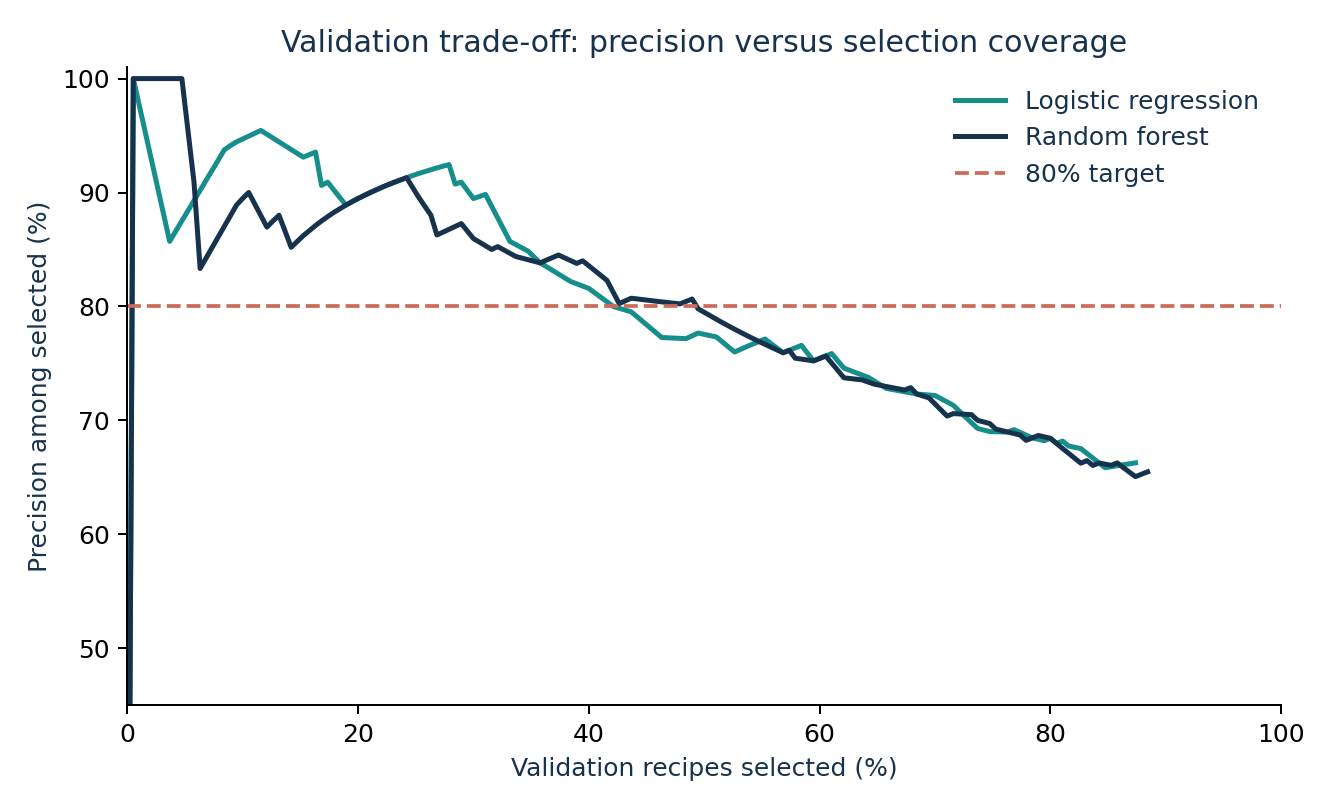

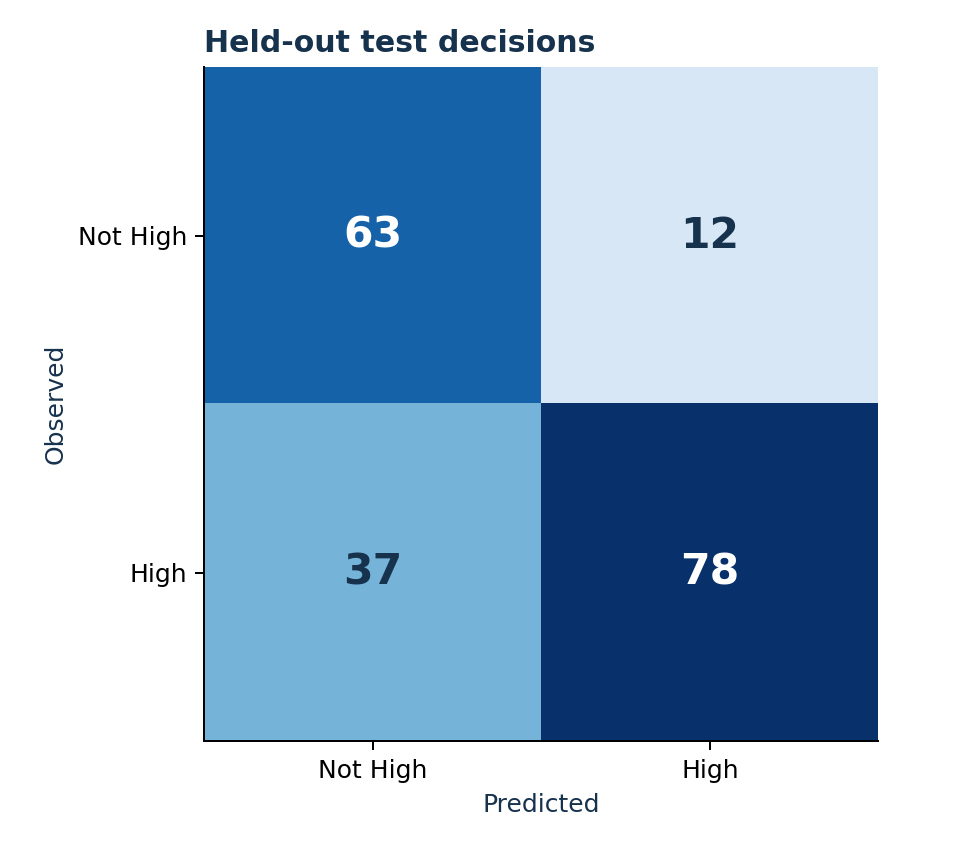

In [8]:
from IPython.display import Image
selected=results["selected"]; test=selected["test"]; dummy=results["dummy_test"]
display(pd.DataFrame([
 {"policy":"Feature every recipe","precision":dummy["precision"],
  "recall":dummy["recall"],"selected":dummy["selected_count"],"coverage":dummy["selection_coverage"]},
 {"policy":f"{selected['model']} at threshold {selected['threshold_chosen_on_validation']:.4f}",
  "precision":test["precision"],"recall":test["recall"],
  "selected":test["selected_count"],"coverage":test["selection_coverage"]}
]))
print("Selected model held-out confusion counts:",
      {k:test[k] for k in ("true_positive","false_positive","false_negative","true_negative")})
print("Wilson 95% interval for selected precision:",
      selected["test_precision_wilson_95_percent"])
display(Image(filename="precision_coverage.png",width=700))
display(Image(filename="test_confusion_matrix.png",width=530))


**Held-out result.** The chosen random forest selected **90 of 190** test recipes. **78 of those 90** had a High label, so precision was **86.7%**, with **67.8% recall** and **47.4% selection coverage**. It missed 37 High recipes and selected 12 recipes with blank labels. Its 95% Wilson precision interval is **78.1%–92.2%**, which crosses the 80% target. The point estimate clears the target, but the evidence does not guarantee that future performance will.


## Business metric and initial value

For each proposed homepage batch, calculate **High-label precision = selected recipes later confirmed High ÷ all selected recipes**. Track **selection coverage = selected recipes ÷ all eligible recipes** beside it. The product's stated threshold is **80% precision**.

On the same **validation set**, logistic regression reaches **64/80 = 80.0% precision** and selects **80/190 = 42.1%** of recipes. Random forest reaches **75/93 = 80.6% precision** and selects **93/190 = 48.9%**. Random forest therefore meets the target while offering 13 more options. After choosing it on validation, its independent **test-set** precision is **78/90 = 86.7%**, with **90/190 = 47.4%** coverage. For context, selecting every test recipe gives **115/190 = 60.5%** High. These are historical label comparisons; no increase in traffic or subscriptions was measured.

In [9]:
business_metric = pd.DataFrame([
 {"split":"Validation","policy":"Logistic regression","High selected":64,"selected":80,
  "precision":64/80,"coverage":80/190},
 {"split":"Validation","policy":"Random forest","High selected":75,"selected":93,
  "precision":75/93,"coverage":93/190},
 {"split":"Test","policy":"Select all reference","High selected":115,"selected":190,
  "precision":115/190,"coverage":190/190},
 {"split":"Test","policy":"Chosen random forest","High selected":78,"selected":90,
  "precision":78/90,"coverage":90/190},
])
business_metric["precision (%)"]=(business_metric["precision"]*100).round(1)
business_metric["coverage (%)"]=(business_metric["coverage"]*100).round(1)
display(business_metric.drop(columns=["precision","coverage"]))


,split,policy,High selected,selected,precision (%),coverage (%)
0,Validation,Logistic regression,64,80,80.0,42.1
1,Validation,Random forest,75,93,80.6,48.9
2,Test,Select all reference,115,190,60.5,100.0
3,Test,Chosen random forest,78,90,86.7,47.4


## Final summary and recommendations

The random forest is the stronger historical selection rule under the chosen precision-and-coverage objective. Before operational use, confirm the meaning of blank traffic labels and record **all eligible candidate recipes**, not only those historically featured. Log feature values available before selection, homepage exposure, dates, subsequent traffic, and subscription outcomes. Run a monitored prospective comparison with the current editorial policy; evaluate precision, coverage, category mix, false positives, and actual subscription change. Retrain and retest on a later time window before scaling.

**Evidence limits.** The dataset contains no timestamps, no randomized exposure, and no subscription measurements. It cannot establish that selecting a recipe caused traffic or subscriptions to rise. The historical featured set may not represent future candidates. No model has been deployed by this notebook.
